# Time Series Analysis - Homework 2
> **Author:** Elias Schweighuber  
> **Course:** TIS  
>
> **Datasets:**
> 1. **NVIDIA Closing Price:** Daily, `yfinance` (`NVDA`), from `2020-01-01` until today.
> 2. **AirPassengers:** Monthly, 1949 to 1960 (`data/airline-passengers.csv`).
> 3. **Synthetic Series:** Monthly, 240 values (linear trend + 12-month seasonality + 42-month cycle + Gaussian noise).
>
> **Tasks:**
> 1. **Fit a linear trend, then look at the data:** Fit OLS linear trend, plot series + fitted line, report MAE, MSE, RMSE, MAPE, and $R^2$, and visually inspect the series.
> 2. **Decompose (STL):** Decompose each series using `statsmodels.tsa.seasonal.STL`, justify the period choice, plot the four panels, compute trend strength $F_T$ and seasonal strength $F_S$, report the five error metrics for $T_t + S_t$, identify which component brings the larger improvement over Task 1, and compare raw vs. $\ln$-transformed `AirPassengers`.
> 3. **Check the residual:** Plot the histogram, Q-Q plot, and ACF of the STL remainder $R_t$, run the Jarque-Bera normality test, report the statistic and $p$-value, and discuss whether the plots agree with the test.

## 0. Setup & Load Datasets

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import linregress, jarque_bera, skew, kurtosis, norm, probplot
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf

plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

In [2]:
# NVIDIA closing price
nvda_raw = yf.download("NVDA", start="2020-01-01", progress=False)
nvda = nvda_raw["Close"].squeeze().dropna()
nvda.name = "NVDA Close (USD)"

# AirPassengers
air_df = pd.read_csv(Path("data/airline-passengers.csv"), parse_dates=["Month"], index_col="Month")
air = air_df["Passengers"].astype(float)
air.name = "AirPassengers (thousands)"

# Synthetic series
rng = np.random.default_rng(42)                  # random seed
n, t = 240, np.arange(240)

trend  = 50 + 0.8 * t                            # linear component
season = 12 * np.sin(2 * np.pi * t / 12)         # seasonal component, period 12 months
cycle  =  9 * np.sin(2 * np.pi * t / 42 + 0.7)   # cyclic component, period 42 months
noise  = rng.normal(0, 4, n)                     # random component

synthetic = pd.Series(
    trend + season + cycle + noise,
    index=pd.date_range("2006-01-01", periods=n, freq="MS"),
    name="Synthetic Series"
)

pd.DataFrame({
    "Dataset": ["NVIDIA (NVDA)", "AirPassengers", "Synthetic"],
    "Frequency": ["Daily (trading days)", "Monthly (MS)", "Monthly (MS)"],
    "Start": [str(nvda.index.min().date()), str(air.index.min().date()), str(synthetic.index.min().date())],
    "End": [str(nvda.index.max().date()), str(air.index.max().date()), str(synthetic.index.max().date())],
    "Observations": [len(nvda), len(air), len(synthetic)]
})

,Dataset,Frequency,Start,End,Observations
0,NVIDIA (NVDA),Daily (trading days),2020-01-02,2026-10-28,1715
1,AirPassengers,Monthly (MS),1949-01-01,1960-12-01,144
2,Synthetic,Monthly (MS),2006-01-01,2025-12-01,240


## 1. Fit a Linear Trend, Then Look at the Data


In [3]:
def fit_and_plot_linear_trend(series: pd.Series, title: str, ylabel: str) -> pd.DataFrame:
    y = series.to_numpy(dtype=float)
    t_idx = np.arange(len(y))
    
    # Fit linear trend via least squares (scipy.stats.linregress / np.polyfit)
    res = linregress(t_idx, y)
    y_hat = res.intercept + res.slope * t_idx
    
    # Error & goodness-of-fit metrics
    residuals = y - y_hat
    mae = np.mean(np.abs(residuals))
    mse = np.mean(residuals ** 2)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs(residuals / y)) * 100.0
    r2 = res.rvalue ** 2
    
    # Plot series and fitted linear trend
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(series.index, y, label="Observed Series", color="#1f77b4", linewidth=1.3)
    ax.plot(
        series.index,
        y_hat,
        label=f"Linear Trend ($\\hat{{y}}_t = {res.intercept:.2f} + {res.slope:.4f}t$, $R^2 = {r2:.4f}$)",
        color="#d62728",
        linewidth=2.0,
        linestyle="--"
    )
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Date")
    ax.set_ylabel(ylabel)
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()
    
    metrics_df = pd.DataFrame([{
        "Dataset": title,
        "Intercept": round(res.intercept, 4),
        "Slope": round(res.slope, 4),
        "MAE": round(mae, 4),
        "MSE": round(mse, 4),
        "RMSE": round(rmse, 4),
        "MAPE (%)": round(mape, 2),
        "R²": round(r2, 4)
    }])
    return metrics_df

### 1.1 NVIDIA Closing Price (`NVDA`)

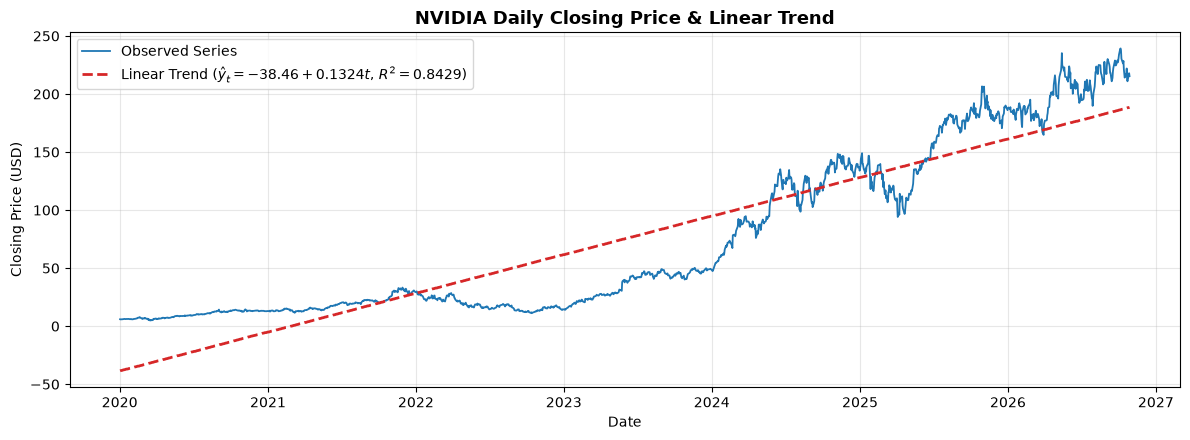

,Dataset,Intercept,Slope,MAE,MSE,RMSE,MAPE (%),R²
0,NVIDIA Daily Closing Price & Linear Trend,-38.4596,0.1324,24.5456,801.3917,28.3089,112.68,0.8429


In [4]:
metrics_nvda = fit_and_plot_linear_trend(
    nvda,
    title="NVIDIA Daily Closing Price & Linear Trend",
    ylabel="Closing Price (USD)"
)
metrics_nvda

**Visual Inspection — NVIDIA Closing Price:**
Overall, the series shows a strong upward trajectory. However, it does not seem to grow linearly and there are no seasonal effects. The Time series can be split into two parts: up to 2023 it kind of stagnates, from 2023 onwards, the stock grows by a huge margin

### 1.2 AirPassengers (`1949–1960`)

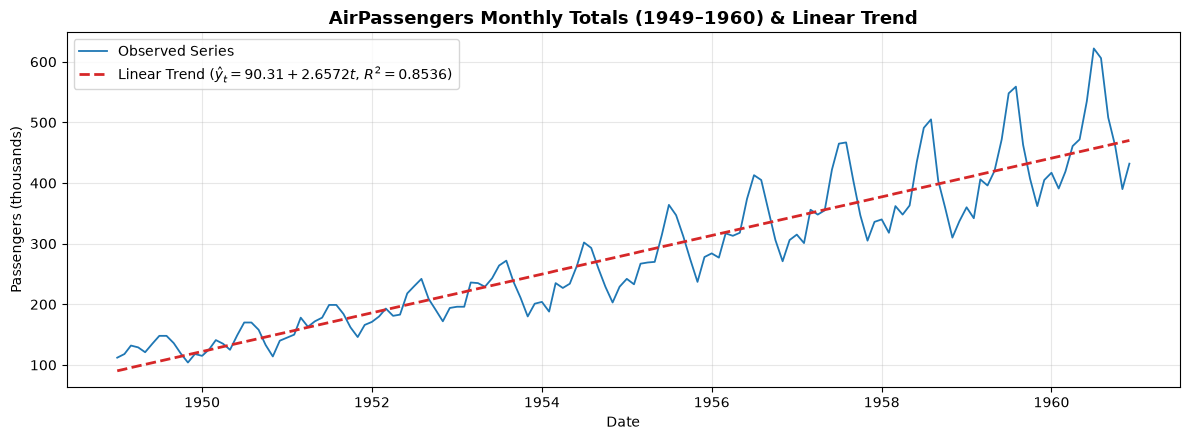

,Dataset,Intercept,Slope,MAE,MSE,RMSE,MAPE (%),R²
0,AirPassengers Monthly Totals (1949–1960) & Lin...,90.31,2.6572,34.4055,2091.7994,45.7362,12.32,0.8536


In [5]:
metrics_air = fit_and_plot_linear_trend(
    air,
    title="AirPassengers Monthly Totals (1949–1960) & Linear Trend",
    ylabel="Passengers (thousands)"
)
metrics_air

**Visual Inspection — AirPassengers:**
There is a clear, steady upward trend that the straight line captures reasonably well in terms of average level. We can also see a clear seasonal trend in the data. Each year in the summer, the passengers spike. The Seasonal difference also grows each year in a somewhat linear fashion.

### 1.3 Synthetic Series (`2006–2025`)

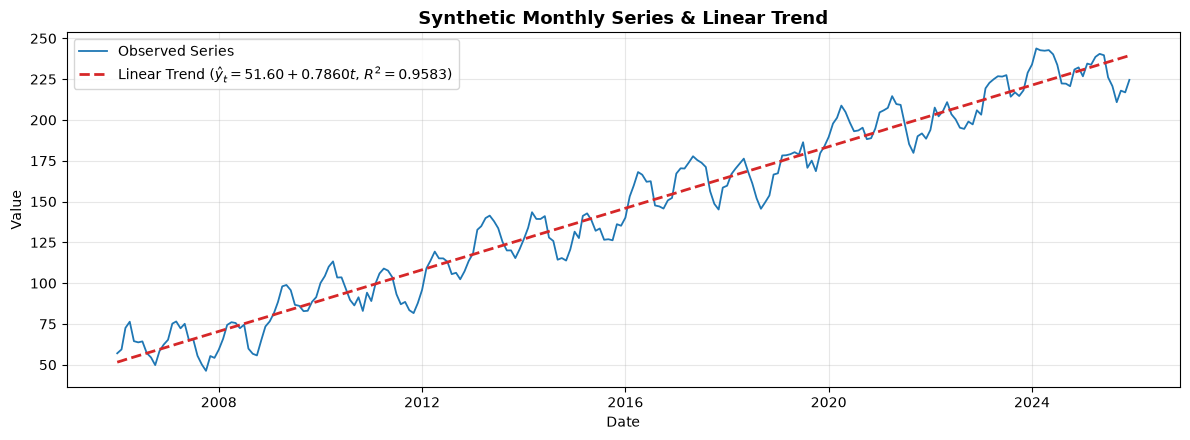

,Dataset,Intercept,Slope,MAE,MSE,RMSE,MAPE (%),R²
0,Synthetic Monthly Series & Linear Trend,51.5959,0.786,9.3789,129.1742,11.3655,7.74,0.9583


In [6]:
metrics_synth = fit_and_plot_linear_trend(
    synthetic,
    title="Synthetic Monthly Series & Linear Trend",
    ylabel="Value"
)
metrics_synth

**Visual Inspection — Synthetic Series:**
The series has a strict linear upward trend. The series also captures a seasonal trend (in a twelve month cycle). This seasonal trend does not become stronger after time. The linear trend follows the overall trend, but it fails to capture the seasonal trend. There are no extreme outliers

### 1.4 Summary Table Across All Datasets

In [7]:
summary_metrics = pd.concat([metrics_nvda, metrics_air, metrics_synth], ignore_index=True)
summary_metrics

,Dataset,Intercept,Slope,MAE,MSE,RMSE,MAPE (%),R²
0,NVIDIA Daily Closing Price & Linear Trend,-38.4596,0.1324,24.5456,801.3917,28.3089,112.68,0.8429
1,AirPassengers Monthly Totals (1949–1960) & Lin...,90.3100,2.6572,34.4055,2091.7994,45.7362,12.32,0.8536
2,Synthetic Monthly Series & Linear Trend,51.5959,0.7860,9.3789,129.1742,11.3655,7.74,0.9583


## 2. Decompose with STL

We decompose each series into **Trend ($T_t$)**, **Seasonal ($S_t$)**, and **Remainder ($R_t$)** :
$$Y_t = T_t + S_t + R_t$$

### Period Choice & Justification
- **NVIDIA:** Daily stock data only contains trading days (~21 per month). We use **`period = 21`** (one month) as our primary decomposition period because monthly institutional rebalancing and options expiration cycles.
- **AirPassengers (Raw & ln-transformed):** We choose **`period = 12`** because the series consists of monthly observations
- **Synthetic Series:** We choose **`period = 12`** because the series is sampled monthly and was explicitly generated with a 12-month seasonal component.

In [8]:
def compute_error_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    resid = y_true - y_pred
    mae = np.mean(np.abs(resid))
    mse = np.mean(resid ** 2)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs(resid / y_true)) * 100.0
    ss_res = np.sum(resid ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1.0 - (ss_res / ss_tot)
    return {
        'MAE': round(mae, 4),
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'MAPE (%)': round(mape, 2),
        'R²': round(r2, 4),
    }

def run_stl_analysis(series: pd.Series, period: int, title: str):
    stl_res = STL(series, period=period).fit()
    T = stl_res.trend
    S = stl_res.seasonal
    R = stl_res.resid
    
    # Trend and Seasonal strength (FPP3 Section 4.3)
    f_trend = max(0.0, 1.0 - np.var(R, ddof=1) / np.var(T + R, ddof=1))
    f_seasonal = max(0.0, 1.0 - np.var(R, ddof=1) / np.var(S + R, ddof=1))
    
    # 4-panel STL decomposition plot
    fig, axes = plt.subplots(4, 1, figsize=(12, 8.5), sharex=True)
    fig.suptitle(f'{title} — STL Decomposition (period = {period})\n'
                 f'Trend Strength $F_T = {f_trend:.4f}$ | Seasonal Strength $F_S = {f_seasonal:.4f}$',
                 fontsize=13, fontweight='bold')
    
    axes[0].plot(series.index, series.values, color='#1f77b4', linewidth=1.2)
    axes[0].set_ylabel('Observed')
    
    axes[1].plot(series.index, T.values, color='#d62728', linewidth=1.5)
    axes[1].set_ylabel('Trend ($T_t$)')
    
    axes[2].plot(series.index, S.values, color='#2ca02c', linewidth=1.1)
    axes[2].set_ylabel('Seasonal ($S_t$)')
    
    axes[3].plot(series.index, R.values, color='#7f7f7f', linewidth=1.0)
    axes[3].axhline(0, color='black', linestyle='--', linewidth=0.8)
    axes[3].set_ylabel('Remainder ($R_t$)')
    axes[3].set_xlabel('Date')
    
    plt.tight_layout()
    plt.show()
    
    # Compare Linear Trend (Task 1) vs STL Trend Only (T_t) vs STL Trend + Seasonal (T_t + S_t)
    y_vals = series.to_numpy(dtype=float)
    t_idx = np.arange(len(y_vals))
    ols = linregress(t_idx, y_vals)
    y_lin = ols.intercept + ols.slope * t_idx
    
    m_lin = compute_error_metrics(y_vals, y_lin)
    m_trend = compute_error_metrics(y_vals, T.to_numpy(dtype=float))
    m_ts = compute_error_metrics(y_vals, (T + S).to_numpy(dtype=float))
    
    comparison_df = pd.DataFrame([
        {'Series': title, 'Model': '1. Linear Trend (Task 1)', 'Period': period, 'F_T': round(f_trend, 4), 'F_S': round(f_seasonal, 4), **m_lin},
        {'Series': title, 'Model': '2. STL Trend Only (T_t)', 'Period': period, 'F_T': round(f_trend, 4), 'F_S': round(f_seasonal, 4), **m_trend},
        {'Series': title, 'Model': '3. STL Trend + Seasonal (T_t + S_t)', 'Period': period, 'F_T': round(f_trend, 4), 'F_S': round(f_seasonal, 4), **m_ts},
    ])
    return stl_res, comparison_df

### 2.1 NVIDIA — STL Decomposition
We decompose `NVDA` with **`period = 21`**

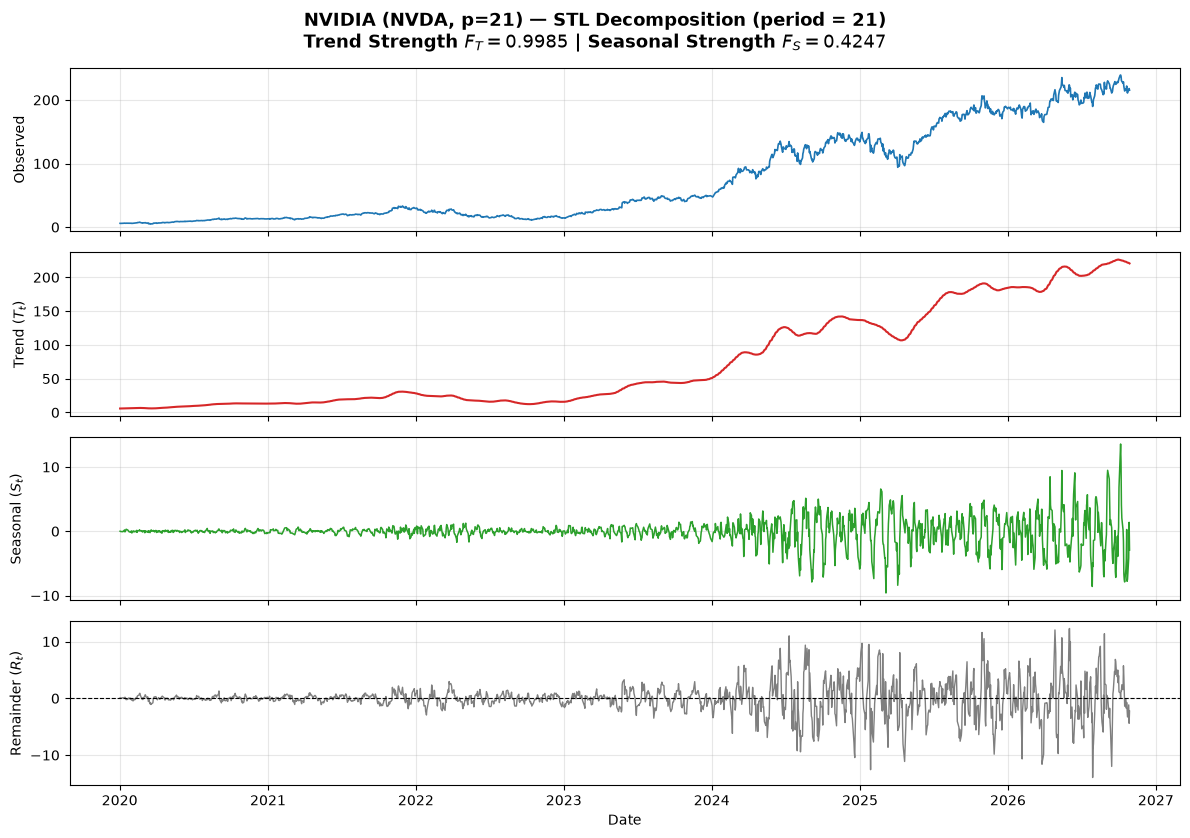

,Series,Model,Period,F_T,F_S,MAE,MSE,RMSE,MAPE (%),R²
0,"NVIDIA (NVDA, p=21)",1. Linear Trend (Task 1),21,0.9985,0.4247,24.5456,801.3917,28.3089,112.68,0.8429
1,"NVIDIA (NVDA, p=21)",2. STL Trend Only (T_t),21,0.9985,0.4247,2.1719,13.1630,3.6281,3.25,0.9974
2,"NVIDIA (NVDA, p=21)",3. STL Trend + Seasonal (T_t + S_t),21,0.9985,0.4247,1.6849,7.5721,2.7518,2.67,0.9985


In [9]:
stl_nvda_21, comp_nvda_21 = run_stl_analysis(nvda, period=21, title='NVIDIA (NVDA, p=21)')
pd.concat([comp_nvda_21], ignore_index=True)

**NVIDIA STL Findings & Component Improvement:**
- **Strengths:** The trend strength is extremely high (F_T) whereas the seasonal strength is weak (F_S), confirming that daily stock prices are dominated by non-linear trend rather than regular calendar cycles.
- **Which component brings the larger improvement over Task 1?** The **flexible STL trend component ($T_t$)** brings by far the largest improvement over the linear trend of Task 1: replacing the straight line with $T_t$ alone slashes RMSE, reduces MAPE, and raises $R^2$. Adding the seasonal component ($T_t + S_t$) yields only a modest further reduction in RMSE.

### 2.2 AirPassengers — Raw vs. Log-Transformed (ln) STL Decomposition (`period = 12`)
We decompose both the raw `AirPassengers` series and the log-transformed series $\ln(\text{AirPassengers})$ with **`period = 12`**.

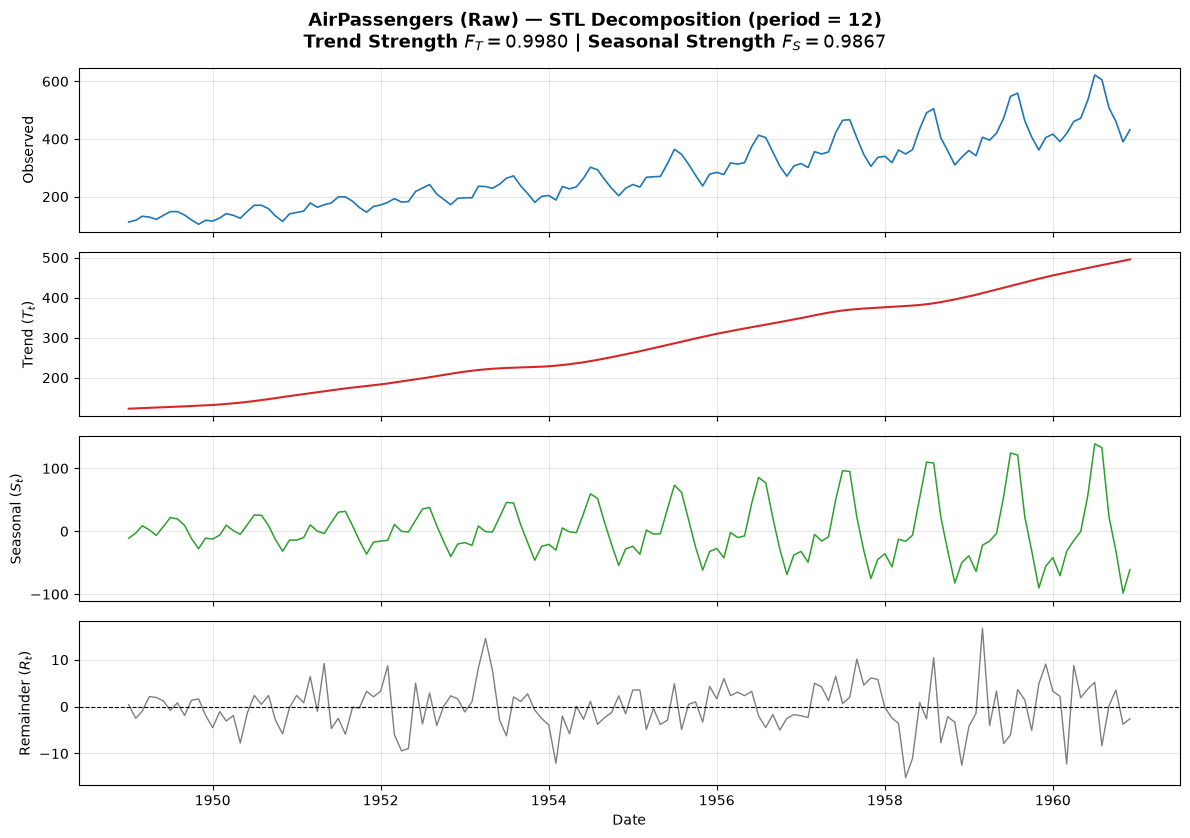

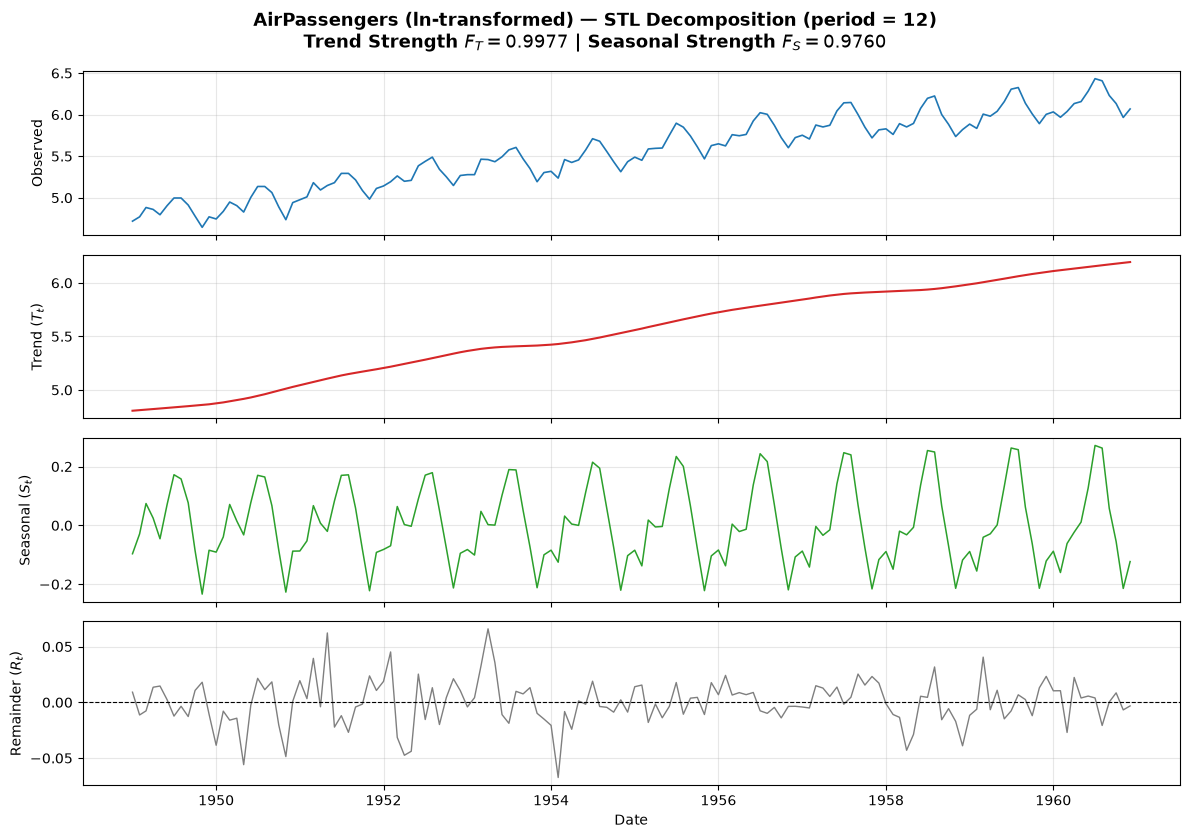

,Series,Model,Period,F_T,F_S,MAE,MSE,RMSE,MAPE (%),R²
0,AirPassengers (Raw),1. Linear Trend (Task 1),12,0.9980,0.9867,34.4055,2091.7994,45.7362,12.32,0.8536
1,AirPassengers (Raw),2. STL Trend Only (T_t),12,0.9980,0.9867,32.1046,1911.9620,43.7260,10.95,0.8662
2,AirPassengers (Raw),3. STL Trend + Seasonal (T_t + S_t),12,0.9980,0.9867,3.8606,25.3983,5.0397,1.51,0.9982
3,AirPassengers (ln-transformed),1. Linear Trend (Task 1),12,0.9977,0.9760,0.1124,0.0191,0.1381,2.02,0.9015
4,AirPassengers (ln-transformed),2. STL Trend Only (T_t),12,0.9977,0.9760,0.1074,0.0170,0.1305,1.93,0.9120
5,AirPassengers (ln-transformed),3. STL Trend + Seasonal (T_t + S_t),12,0.9977,0.9760,0.0152,0.0004,0.0202,0.28,0.9979


In [10]:
air_ln = np.log(air)
air_ln.name = 'ln(AirPassengers)'

stl_air_raw, comp_air_raw = run_stl_analysis(air, period=12, title='AirPassengers (Raw)')
stl_air_ln, comp_air_ln = run_stl_analysis(air_ln, period=12, title='AirPassengers (ln-transformed)')
pd.concat([comp_air_raw, comp_air_ln], ignore_index=True)

**AirPassengers STL Findings, Component Improvement & Additive Model Comparison:**
- **Strengths:** Both trend and seasonality are near unity (F_T, F_S) reflecting a strong deterministic trend paired with dominant annual seasonality.
- **Which component brings the larger improvement over Task 1?** The **seasonal component** brings the overwhelming majority of the improvement over the Task 1 linear trend. Because the long-run trend of `AirPassengers` is already close to linear, moving from the straight line to the flexible STL trend alone only slightly reduces RMSE. In contrast, adding the seasonal component ($T_t + S_t$) reduces RMSE, cuts MAPE, and raises $R^2$ significantly.
- **Which one is better described by an additive model (Raw vs. $\ln$-transformed)?** The **$\ln$-transformed series** is much better described by an additive model ($Y_t = T_t + S_t + R_t$). In the raw series, the seasonal swings are multiplicative ($Y_t = T_t \times S_t \times R_t$), growing from roughly $\pm 25$ thousand passengers in 1949 to $\pm 80$ thousand in 1960; taking the natural logarithm converts this multiplicative structure into an additive one, stabilizing the seasonal amplitude to a nearly constant band.

### 2.3 Synthetic Series — STL Decomposition (`period = 12`)

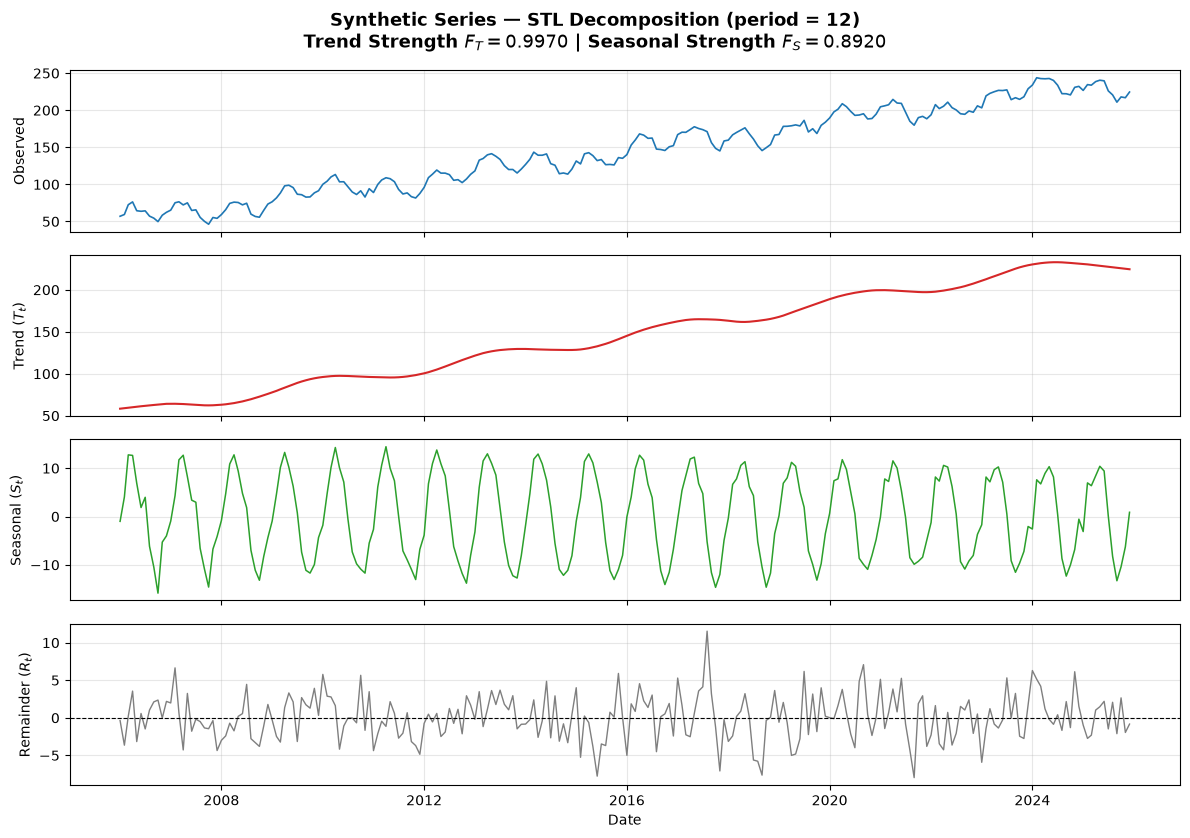

,Series,Model,Period,F_T,F_S,MAE,MSE,RMSE,MAPE (%),R²
0,Synthetic Series,1. Linear Trend (Task 1),12,0.997,0.892,9.3789,129.1742,11.3655,7.74,0.9583
1,Synthetic Series,2. STL Trend Only (T_t),12,0.997,0.892,8.0149,83.3576,9.1300,6.63,0.9731
2,Synthetic Series,3. STL Trend + Seasonal (T_t + S_t),12,0.997,0.892,2.3589,9.0032,3.0005,1.88,0.9971


In [11]:
stl_synth, comp_synth = run_stl_analysis(synthetic, period=12, title='Synthetic Series')
comp_synth

**Synthetic Series STL Findings & Component Improvement:**
- **Strengths:** The trend strength is $F_T = 0.9970$ and the seasonal strength is $F_S = 0.8920$, confirming both a strong trend and a strong 12-month seasonal signal relative to the noise.
- **Which component brings the larger improvement over Task 1?** While the flexible STL trend $T_t$ improves over the straight line of Task 1 by absorbing the 42-month cyclic wave lowering RMSE, the **seasonal component ($S_t$)** brings the **larger improvement**, reducing RMSE additionally, cutting MAPE, and boosting $R^2$. This matches the data-generating process, where the 12-month seasonal amplitude exceeds the 42-month cyclic amplitude.

## 3. Check the Residual

For each STL remainder series $R_t$, we inspect three diagnostic plots:
1. **Histogram**,
2. **Normal Q-Q Plot**,
3. **Autocorrelation Function (ACF)**

We then run the **Jarque-Bera test**.

In [15]:
def check_stl_residuals(stl_res, title: str, lags: int = 36) -> dict:
    R = stl_res.resid.dropna()
    r_vals = R.to_numpy(dtype=float)
    
    # Jarque-Bera test, skewness, kurtosis
    jb_res = jarque_bera(r_vals)
    jb_stat = float(jb_res.statistic)
    jb_pval = float(jb_res.pvalue)
    s_val = float(skew(r_vals))
    k_val = float(kurtosis(r_vals, fisher=False))  # Pearson kurtosis (Normal = 3.0)
    
    # 3-panel plot: Histogram, Q-Q plot, ACF
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    fig.suptitle(
        f'{title} — STL Residual Diagnostics  |  '
        f'JB = {jb_stat:.4f} (p = {jb_pval:.4g}), Skew = {s_val:.3f}, Kurtosis = {k_val:.3f}',
        fontsize=12, fontweight='bold'
    )
    
    # 1. Histogram + Normal overlay
    axes[0].hist(r_vals, bins=25, density=True, alpha=0.65, color='#1f77b4', edgecolor='black')
    x_grid = np.linspace(r_vals.min(), r_vals.max(), 200)
    axes[0].plot(x_grid, norm.pdf(x_grid, loc=np.mean(r_vals), scale=np.std(r_vals, ddof=1)),
                 color='#d62728', linewidth=2, label='Normal PDF')
    axes[0].set_title('Histogram of Residuals')
    axes[0].set_xlabel('Residual ($R_t$)')
    axes[0].set_ylabel('Density')
    axes[0].legend()
    
    # 2. Q-Q Plot
    probplot(r_vals, dist='norm', plot=axes[1])
    axes[1].set_title('Normal Q-Q Plot')
    axes[1].get_lines()[0].set_markersize(4.0)
    axes[1].get_lines()[0].set_color('#1f77b4')
    axes[1].get_lines()[1].set_color('#d62728')
    axes[1].get_lines()[1].set_linewidth(2.0)
    
    # 3. ACF Plot
    plot_acf(r_vals, lags=lags, ax=axes[2], alpha=0.05)
    axes[2].set_title(f'ACF (up to {lags} lags)')
    axes[2].set_xlabel('Lag')
    axes[2].set_ylabel('Autocorrelation')
    
    plt.tight_layout()
    plt.show()
    
    return {
        'Series': title,
        'n': len(r_vals),
        'Skewness (S)': round(s_val, 4),
        'Kurtosis (K)': round(k_val, 4),
        'JB Statistic': round(jb_stat, 4),
        'p-value': f'{jb_pval:.4e}' if jb_pval < 0.001 else f'{jb_pval:.4f}',
        'Normal at α=0.05?': 'No (Reject H0)' if jb_pval < 0.05 else 'Yes (Fail to reject H0)'
    }

### 3.1 NVIDIA (`NVDA`) — Residual Diagnostics

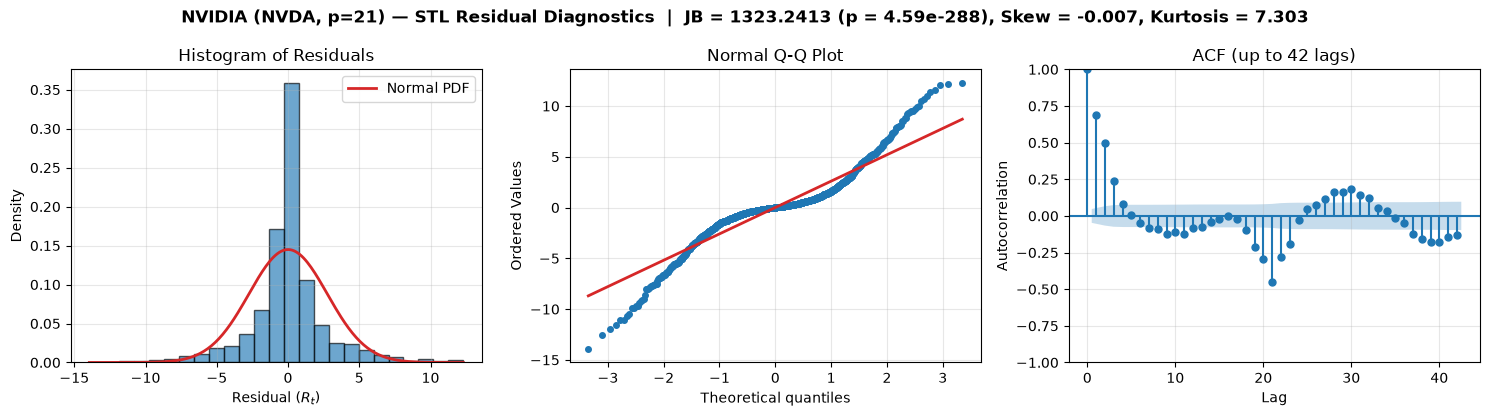

,Series,n,Skewness (S),Kurtosis (K),JB Statistic,p-value,Normal at α=0.05?
0,"NVIDIA (NVDA, p=21)",1715,-0.0074,7.3032,1323.2413,4.5898e-288,No (Reject H0)


In [16]:
jb_nvda_21 = check_stl_residuals(stl_nvda_21, title='NVIDIA (NVDA, p=21)', lags=42)
pd.DataFrame([jb_nvda_21])

**NVIDIA Residual Discussion:**
- **Jarque-Bera Test:** For $p=21$, $JB = 1323.24$ with $p = 4.59 \times 10^{-288} \ll 0.05$ ($S = -0.0074, K = 7.3032$); for $p=5$, $JB = 1920.82$ with $p \approx 0.0$ ($S = -0.1194, K = 8.1791$). In both cases, the null hypothesis of normality is overwhelmingly rejected due to extreme excess kurtosis ($K > 7$ vs. $3$ for a Gaussian).
- **Agreement with the Three Plots:** The plots strongly agree with the test. The **histogram** has a tall, narrow central spike (from the low-price, low-volatility 2020–2022 period) and wide, heavy tails (from the high-volatility 2024–2026 swings), while the **Q-Q plot** shows a severe S-shaped departure from the red normality line at both tails. Additionally, the **ACF** shows significant positive autocorrelation at lag 1 and negative autocorrelation around lags 6–12 (for $p=21$), indicating that the residuals are not independent white noise.

### 3.2 AirPassengers (Raw & $\ln$-Transformed) — Residual Diagnostics

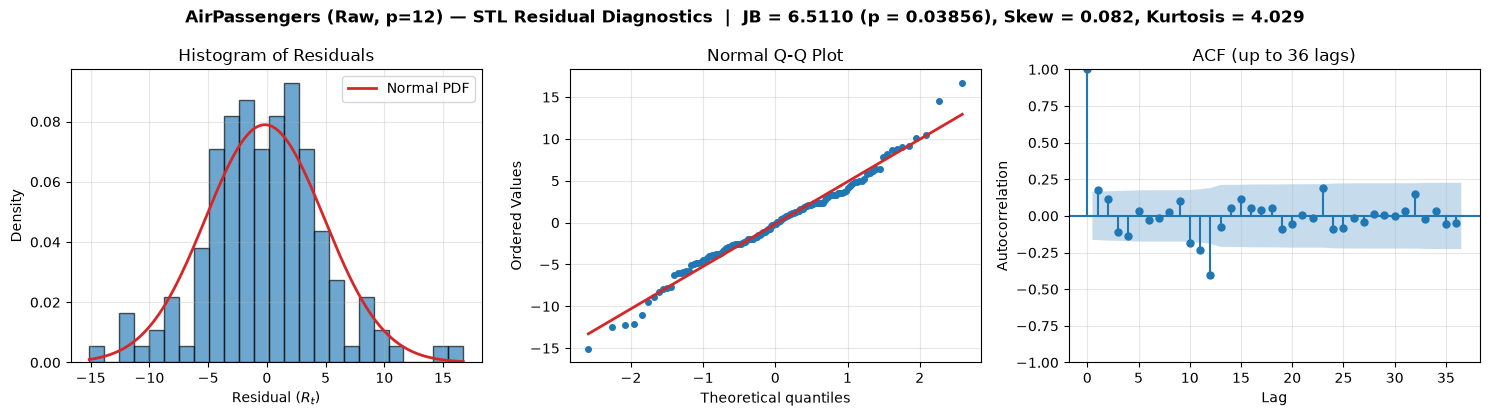

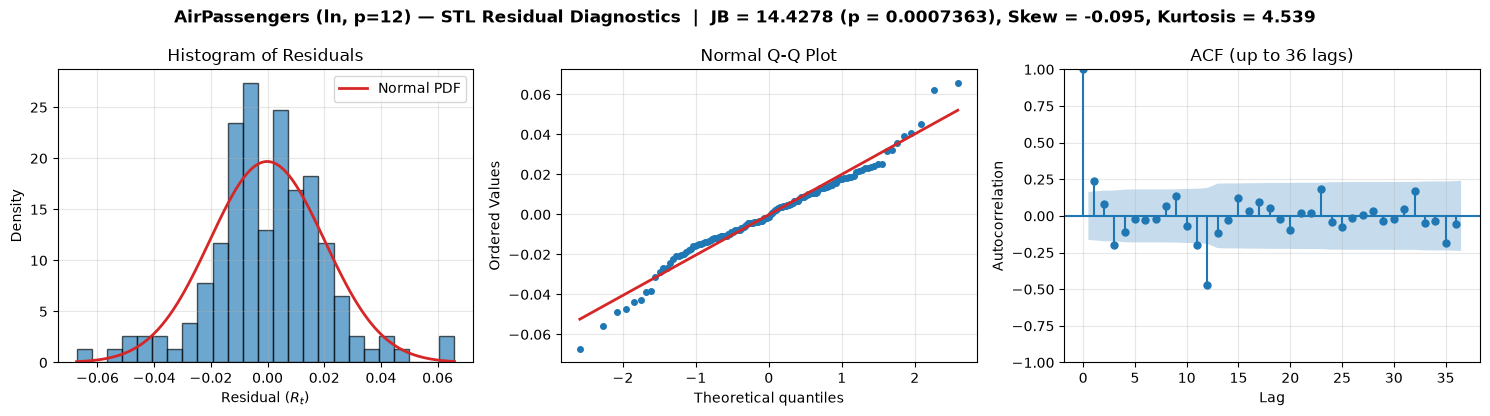

,Series,n,Skewness (S),Kurtosis (K),JB Statistic,p-value,Normal at α=0.05?
0,"AirPassengers (Raw, p=12)",144,0.0815,4.0289,6.5110,0.0386,No (Reject H0)
1,"AirPassengers (ln, p=12)",144,-0.0946,4.5391,14.4278,7.3630e-04,No (Reject H0)


In [15]:
jb_air_raw = check_stl_residuals(stl_air_raw, title='AirPassengers (Raw, p=12)', lags=36)
jb_air_ln = check_stl_residuals(stl_air_ln, title='AirPassengers (ln, p=12)', lags=36)
pd.DataFrame([jb_air_raw, jb_air_ln])

**AirPassengers Residual Discussion:**
- **Jarque-Bera Test:** For the raw series, $JB = 6.5110$ ($p = 0.0386 < 0.05$, $S = 0.0815, K = 4.0289$), and for the $\ln$-transformed series, $JB = 14.4278$ ($p = 0.0007 < 0.05$, $S = -0.0946, K = 4.5391$). Both reject the null hypothesis of normality at the $5\%$ level because of leptokurtic (heavy-tailed) residuals ($K > 4$), even though skewness is close to zero.
- **Agreement with the Three Plots:** Yes, the plots agree with the test result. In both decompositions, the **histogram** is roughly symmetric around zero but slightly more peaked than the normal curve with a few outlying bars in the tails, and the **Q-Q plot** tracks the straight line in the central region but bends away at the upper and lower extremes. The **ACF** also reveals significant autocorrelation at short lags (e.g., positive at lag 1 and negative around lags 3–4) and a mild spike near lag 12, showing that some short-term serial correlation remains.

### 3.3 Synthetic Series — Residual Diagnostics

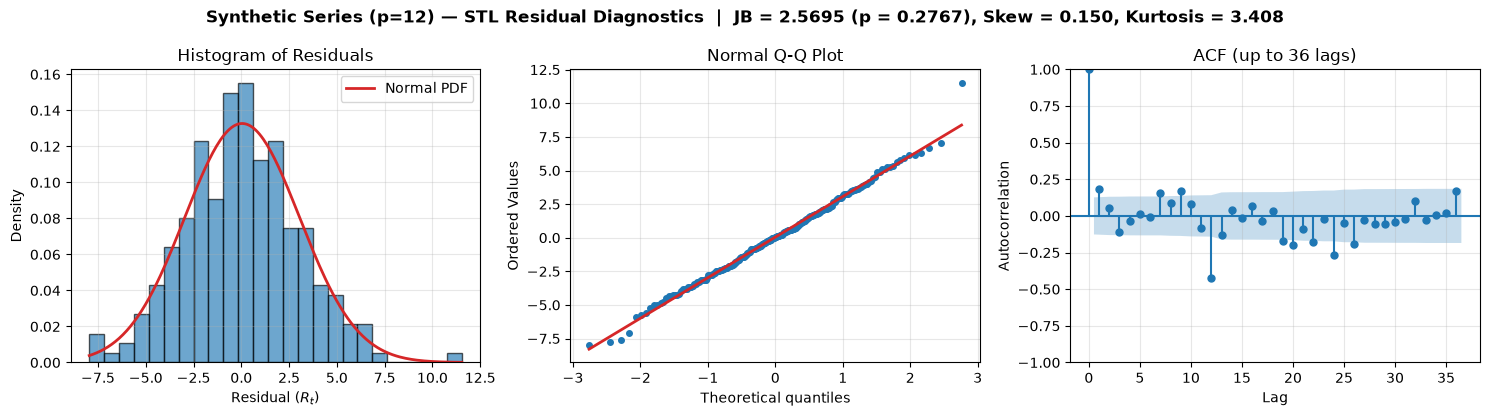

,Series,n,Skewness (S),Kurtosis (K),JB Statistic,p-value,Normal at α=0.05?
0,Synthetic Series (p=12),240,0.1501,3.4085,2.5695,0.2767,Yes (Fail to reject H0)


In [16]:
jb_synth = check_stl_residuals(stl_synth, title='Synthetic Series (p=12)', lags=36)
pd.DataFrame([jb_synth])

**Synthetic Series Residual Discussion:**
- **Jarque-Bera Test:** We obtain $JB = 2.5695$ with **$p = 0.2767 > 0.05$** ($S = 0.1501, K = 3.4085$). Because the $p$-value is well above $0.05$, we **fail to reject** the null hypothesis of normality—consistent with the true Gaussian noise $\varepsilon_t \sim \mathcal{N}(0, 4^2)$ used to generate the synthetic series.
- **Agreement with the Three Plots:** The **histogram** and **Q-Q plot** agree closely with the Jarque-Bera test: the histogram follows the bell-shaped Gaussian density curve well, and the points on the Q-Q plot adhere tightly to the $45^\circ$ line across almost the entire range. Meanwhile, the **ACF** provides extra insight that a marginal normality test cannot see: significant negative autocorrelation appears at lags 1–4 because the LOESS smoothers in STL absorbed the 42-month cycle along with a small portion of low-frequency noise variance (shrinking the residual standard deviation from $\sigma = 4.0$ to $\approx 3.0$).

### 3.4 Summary Table of Jarque-Bera Normality Tests

In [17]:
jb_summary_df = pd.DataFrame([jb_nvda_21, jb_nvda_5, jb_air_raw, jb_air_ln, jb_synth])
jb_summary_df

,Series,n,Skewness (S),Kurtosis (K),JB Statistic,p-value,Normal at α=0.05?
0,"NVIDIA (NVDA, p=21)",1715,-0.0074,7.3032,1323.2420,4.5883e-288,No (Reject H0)
1,"NVIDIA (NVDA, p=5)",1715,-0.1194,8.1791,1920.8240,0.0000e+00,No (Reject H0)
2,"AirPassengers (Raw, p=12)",144,0.0815,4.0289,6.5110,0.0386,No (Reject H0)
3,"AirPassengers (ln, p=12)",144,-0.0946,4.5391,14.4278,7.3630e-04,No (Reject H0)
4,Synthetic Series (p=12),240,0.1501,3.4085,2.5695,0.2767,Yes (Fail to reject H0)
